<h2 style="color:#18453B; margin-top:0;">Midterm Horticultural Repeated Measures App</h2>

<div style="background:#F7FAF7; color:#1A1A1A; border:2px solid #18453B; padding:12px; border-radius:5px;">
<h2 style="color:#18453B; margin-top:0;">Student Information</h2>
<p><b>Name:</b> Rose Elbert </p>
<p><b>Project title:</b> Repeated Measures Utilization in Horticulture</p>
<p><b>GitHub repository:</b> https://github.com/roseelbert/CMSE-830-Midterm </p>
<p><b>Streamlit app:</b> Local, accessible via github or submitted files. I decided not to deploy the app until it is completed for the final.
<p><b>Final slide file:</b> Repeated Measures - Horticultural Applications </p>
</div>

<b>Abstract:</b> Within horticultural sciences, repeated measures designs are seldom utilized. This streamlit resource is intended for horticulture graduate students and professors, in order to promote the benefits of modeling plant physiologicl phenomenons with repeated measures. Two types of data will be analyzed - a power and effect size model that can inform sample size, and an example dataset from my master's work, which consists of postharvest data. The main goal is to teach users how to set up, analyze, and contextualize appropriate usage of repeated measures in their own science. A user would learn how critical sample size is, be able to compare effect sizes, and explore a meaningful visualization of this project. An important limitation of this project is that basic statistical knowledge is required for ease of use, and that this app will not be teaching the foundational concepts behind that, beyond brief definitions and their contextualization within the project.

<b>Project Focus:</b> How does power and detectable effect size in a repeated measures design change based on the # of treatments, n, and variable nesting?

<b>Intended Audience:</b> Applied plant scientists will be able to utilize this app to better design studies to detect intended effects.

In [3]:
##main data
rm = pd.read_csv('rm_power_grid.csv') 
rm.head()

,effect,k_treatments,m_timepoints,rho,epsilon,effect_f,n_per_treatment,subsamples,icc_subsample,effect_label,N_units_total,n_observations_total,effect_f_unit_mean,partial_eta_sq,df1,df2,lambda,power,power_naive_pseudorep,adequate_80
0,between,2,2,0.2,1.0,0.1,3,1,0.0,small,6,12,0.1000,0.0099,1.0,4.0,0.1000,0.0571,0.0571,False
1,between,2,2,0.2,1.0,0.1,3,2,0.1,small,6,24,0.1348,0.0099,1.0,4.0,0.1818,0.0630,0.0691,False
2,between,2,2,0.2,1.0,0.1,3,2,0.3,small,6,24,0.1240,0.0099,1.0,4.0,0.1538,0.0610,0.0691,False
3,between,2,2,0.2,1.0,0.1,3,2,0.5,small,6,24,0.1155,0.0099,1.0,4.0,0.1333,0.0595,0.0691,False
4,between,2,2,0.2,1.0,0.1,3,4,0.1,small,6,48,0.1754,0.0099,1.0,4.0,0.3077,0.0720,0.0929,False


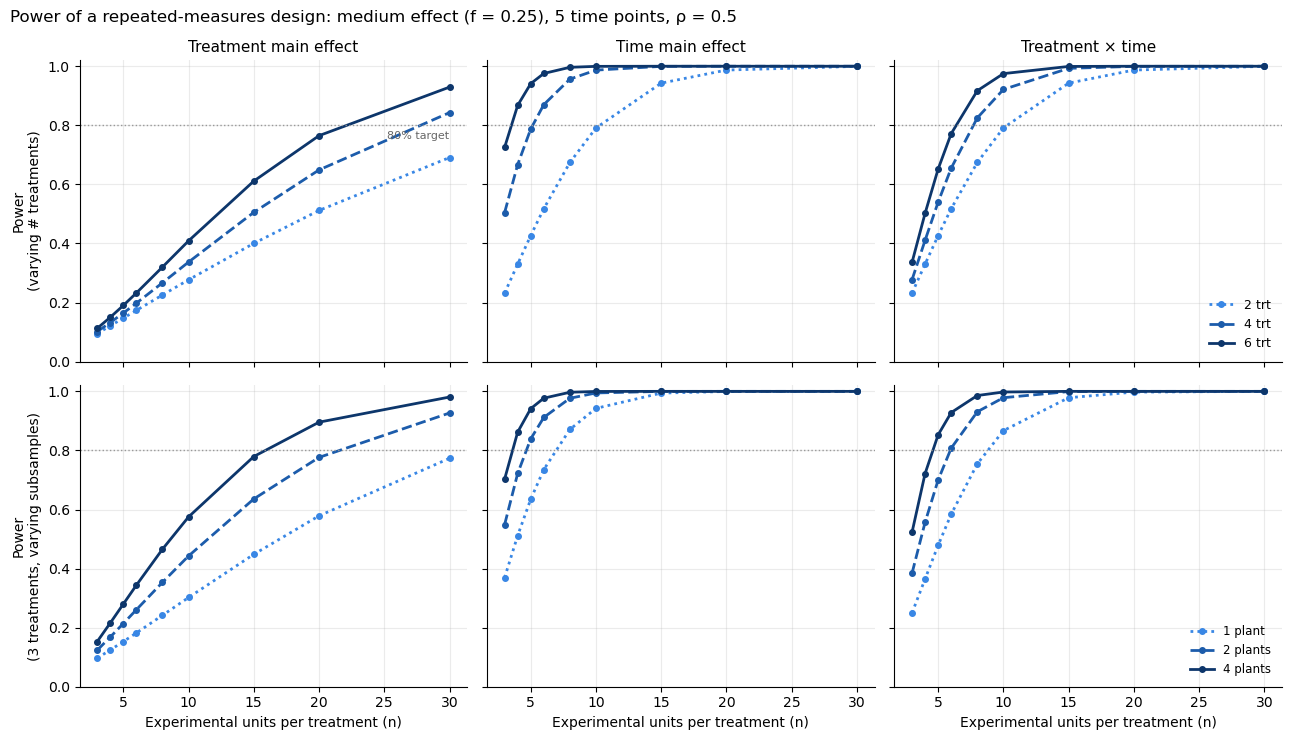

Smallest n per treatment for 80% power (f = 0.25, 5 time points, rho = 0.5)

                                             Treatment main effect  Time main effect  Treatment × time
Design                                                                                                
2 treatments, 1 plant/unit                                      39                11                11
3 treatments, 1 plant/unit                                      32                 7                 9
4 treatments, 1 plant/unit                                      28                 6                 8
6 treatments, 1 plant/unit                                      22                 4                 7
3 treatments, 2 plants/unit (ICC 0.3)                           22                 5                 6
3 treatments, 4 plants/unit (ICC 0.3)                           16                 4                 5
3 treatments, 4 plants as reps (pseudorep.)                      8                 2               

In [6]:
#library
# Concept A analysis
#library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

grid = pd.read_csv("rm_power_grid.csv")

M   = 5      # number of repeated measurements (time points)
RHO = 0.5    # correlation between repeated measurements on the same unit
EPS = 1.0    # sphericity assumed to hold
F   = 0.25   # Cohen's f = medium effect size
ICC = 0.3    # share of variance shared by subsamples within one unit

base = grid[(grid["m_timepoints"] == M) &
            (grid["rho"] == RHO) &
            (grid["epsilon"] == EPS) &
            (grid["effect_f"] == F)]

#f tests
tests  = ["between", "within", "interaction"]
titles = {"between": "Treatment main effect",
          "within": "Time main effect",
          "interaction": "Treatment × time"}

#colors (light blue = fewer, dark blue = more)
k_colors    = {2: "#3987e5", 4: "#1c5cab", 6: "#0d366b"}
nest_colors = {1: "#3987e5", 2: "#1c5cab", 4: "#0d366b"}
styles      = [(0, (1, 1.5)), "--", "-"]

#grid plot
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)

#power vs n for 2, 4, or 6 treatments
for j, test in enumerate(tests):
    ax = axes[0, j]
    for (k, color), ls in zip(k_colors.items(), styles):
        d = base[(base["effect"] == test) &
                 (base["k_treatments"] == k) &
                 (base["subsamples"] == 1)]
        ax.plot(d["n_per_treatment"], d["power"], color=color, lw=2, ls=ls,
                marker="o", ms=4, label=f"{k} trt")
    ax.set_title(titles[test], fontsize=11)

#power vs n for 1, 2, or 4 plants per unit (3 treatments)
for j, test in enumerate(tests):
    ax = axes[1, j]
    for (s, color), ls in zip(nest_colors.items(), styles):
        icc = 0.0 if s == 1 else ICC
        d = base[(base["effect"] == test) &
                 (base["k_treatments"] == 3) &
                 (base["subsamples"] == s) &
                 (base["icc_subsample"] == icc)]
        ax.plot(d["n_per_treatment"], d["power"], color=color, lw=2, ls=ls,
                marker="o", ms=4, label=f"{s} plant{'s' if s > 1 else ''}")

for ax in axes.flat:
    ax.axhline(0.8, color="#999999", lw=1, ls=":")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].text(30, 0.78, "80% target", ha="right", va="top",
                fontsize=8, color="#666666")

for ax in axes[1]:
    ax.set_xlabel("Experimental units per treatment (n)")
axes[0, 0].set_ylabel("Power\n(varying # treatments)")
axes[1, 0].set_ylabel("Power\n(3 treatments, varying subsamples)")
axes[0, 2].legend(frameon=False, fontsize=9, loc="lower right")
axes[1, 2].legend(frameon=False, fontsize=8.5, loc="lower right")
fig.suptitle("Power of a repeated-measures design: medium effect (f = 0.25), "
             "5 time points, ρ = 0.5", fontsize=12, x=0.01, ha="left")
fig.tight_layout()
plt.show()

def rm_power(test, f, N, k, m, rho, eps, alpha=0.05):
    if test == "between":
        lam = f**2 * N * m / (1 + (m - 1) * rho)
        df1, df2 = k - 1, N - k
    elif test == "within":
        lam = f**2 * N * m * eps / (1 - rho)
        df1, df2 = (m - 1) * eps, (N - k) * (m - 1) * eps
    else:  # interaction
        lam = f**2 * N * m * eps / (1 - rho)
        df1, df2 = (k - 1) * (m - 1) * eps, (N - k) * (m - 1) * eps
    f_crit = stats.f.ppf(1 - alpha, df1, df2)
    return stats.ncf.sf(f_crit, df1, df2, lam)

def n_needed(test, k, s=1, icc=0.0, pseudorep=False, target=0.80):
    ns = np.arange(2, 301)
    if pseudorep:
        f_eff, N = F, ns * k * s
    else:
        f_eff, N = F / np.sqrt(icc + (1 - icc) / s), ns * k
    power = rm_power(test, f_eff, N, k, M, RHO, EPS)
    return int(ns[np.argmax(power >= target)])

#summary table
rows = []
for k in [2, 3, 4, 6]:
    rows.append({"Design": f"{k} treatments, 1 plant/unit",
                 **{titles[t]: n_needed(t, k) for t in tests}})
for s in [2, 4]:
    rows.append({"Design": f"3 treatments, {s} plants/unit (ICC {ICC})",
                 **{titles[t]: n_needed(t, 3, s, ICC) for t in tests}})
rows.append({"Design": "3 treatments, 4 plants as reps (pseudorep.)",
             **{titles[t]: n_needed(t, 3, 4, ICC, pseudorep=True) for t in tests}})
summary = pd.DataFrame(rows).set_index("Design")

#summary table
print("Smallest n per treatment for 80% power (f = 0.25, 5 time points, rho = 0.5)\n")
print(summary.to_string())

main = "Treatment main effect"
inter = "Treatment × time"
n_inter_3 = summary.loc["3 treatments, 1 plant/unit", inter]
n_main_3  = summary.loc["3 treatments, 1 plant/unit", main]
n_main_2  = summary.loc["2 treatments, 1 plant/unit", main]
n_main_6  = summary.loc["6 treatments, 1 plant/unit", main]
n_main_s4 = summary.loc[f"3 treatments, 4 plants/unit (ICC {ICC})", main]

In [5]:
##supplemental data
# Replace with your own project dataframe and variable name(s).
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# YOUR CODE HERE
ph = pd.read_csv('ph_combined.txt', delimiter='\t')
ph.head()

table = pd.DataFrame({
    "Variable":["axil_shoot_QI", "apical_shoot_QI", "leaf_QI",
                 "apical_stem_WL", "axil_shoot_WL", "CF"],
    "ID":["AXQI", "APQI", "LFQI", "APWL", "AXWL", "CF"],
    "Measurement":["Axillary Shoot Quality", "Apical Shoot Quality", "Leaf Quality", "Axillary Shoot Water Loss", "Apical Shoot Water Loss", "Chlorophyll Fluorescence"],
    "Data Type":["Ordinal", "Ordinal", "Ordinal", "Continuous", "Continuous", "Continuous"],
    "Category":["Quantitative", "Quantitative", "Quantitative", "Quantitative", "Quantitative", "Quantitative"],
    "Transformation?":["No", "No", "No", "No", "No", "No"],
    "Sample_N":["80", "80", "80", "112", "112", "112"],
        })

table


,Variable,ID,Measurement,Data Type,Category,Transformation?,Sample_N
0,axil_shoot_QI,AXQI,Axillary Shoot Quality,Ordinal,Quantitative,No,80
1,apical_shoot_QI,APQI,Apical Shoot Quality,Ordinal,Quantitative,No,80
2,leaf_QI,LFQI,Leaf Quality,Ordinal,Quantitative,No,80
3,apical_stem_WL,APWL,Axillary Shoot Water Loss,Continuous,Quantitative,No,112
4,axil_shoot_WL,AXWL,Apical Shoot Water Loss,Continuous,Quantitative,No,112
5,CF,CF,Chlorophyll Fluorescence,Continuous,Quantitative,No,112


In [8]:
#previous prototype below

In [7]:
# Repeated Measures Utilization in Horticulture - Streamlit prototype
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import streamlit as st
# from scipy import stats

# st.set_page_config(page_title="Repeated Measures in Horticulture", layout="wide")

# ---------- Title and purpose ----------
# st.title("Repeated Measures Utilization in Horticulture")
# st.write(
#     "Plan a repeated-measures experiment before you run it. Choose your design and "
#     "expected effect size, and see how many experimental units you need to reach "
#     "80% power, then explore how real postharvest basil data look over time."
# )

# ---------- Power formula (noncentral F, same as G*Power) ----------
# def rm_power(test, f, N, k, m, rho, eps, alpha=0.05):
#     if test == "between":
#         lam = f**2 * N * m / (1 + (m - 1) * rho)
#         df1, df2 = k - 1, N - k
#     elif test == "within":
#         lam = f**2 * N * m * eps / (1 - rho)
#         df1, df2 = (m - 1) * eps, (N - k) * (m - 1) * eps
#     else:
#         lam = f**2 * N * m * eps / (1 - rho)
#         df1, df2 = (k - 1) * (m - 1) * eps, (N - k) * (m - 1) * eps
#     return stats.ncf.sf(stats.f.ppf(1 - alpha, df1, df2), df1, df2, lam)

# TESTS = {"Treatment main effect": "between",
#          "Time main effect": "within",
#          "Treatment × time": "interaction"}
# EFFECTS = {"Small (f = 0.10)": 0.10, "Medium (f = 0.25)": 0.25, "Large (f = 0.40)": 0.40}

# tab1, tab2 = st.tabs(["Sample size planner", "Postharvest example"])

# ---------- Tab 1: power planner ----------
# with tab1:
#     with st.sidebar:
#         st.header("Design settings")
#         effect_label = st.selectbox("Expected effect size", list(EFFECTS), index=1)
#         test_label = st.selectbox("Effect you want to detect", list(TESTS))
#         k = st.slider("Number of treatments", 2, 6, 3)
#         m = st.slider("Number of time points", 2, 8, 5)
#         rho = st.slider("Correlation between time points (ρ)", 0.1, 0.9, 0.5, 0.1)
#         s = st.selectbox("Plants measured per experimental unit", [1, 2, 4])
#         icc = st.slider("ICC (how alike plants in one unit are)", 0.0, 0.9, 0.3, 0.1,
#                         disabled=(s == 1))

#     f = EFFECTS[effect_label]
#     test = TESTS[test_label]
#     f_eff = f / np.sqrt((icc if s > 1 else 0) + (1 - (icc if s > 1 else 0)) / s)
#     ns = np.arange(2, 61)
#     power = rm_power(test, f_eff, ns * k, k, m, rho, 1.0)
#     reached = np.nonzero(power >= 0.80)[0]
#     n_req = int(ns[reached[0]]) if reached.size else None

#     c1, c2 = st.columns(2)
#     c1.metric("Units per treatment for 80% power", n_req if n_req else "> 60")
#     c2.metric("Total experimental units", n_req * k if n_req else "—")

#     fig, ax = plt.subplots(figsize=(8, 4))
#     ax.plot(ns, power, color="#2a78d6", lw=2.5)
#     ax.axhline(0.8, color="#999999", ls=":", lw=1)
#     if n_req:
#         ax.axvline(n_req, color="#eb6834", ls="--", lw=1.5)
#         ax.annotate(f"n = {n_req}", (n_req, 0.05), xytext=(5, 0),
#                     textcoords="offset points", color="#eb6834")
#     ax.set_xlabel("Experimental units per treatment (n)")
#     ax.set_ylabel("Power")
#     ax.set_ylim(0, 1.02)
#     ax.set_title(f"{test_label}: {effect_label.lower()}, {k} treatments, {m} time points",
#                  loc="left", fontsize=11)
#     ax.grid(alpha=0.25)
#     ax.spines[["top", "right"]].set_visible(False)
#     st.pyplot(fig)
#     st.caption("Where the curve crosses the dotted line, the design reaches 80% power. "
#                "Assumes sphericity holds and α = 0.05.")

# ---------- Tab 2: postharvest example ----------
# with tab2:
#     ph = pd.read_csv("ph_combined.txt", delimiter="\t")
#     names = {"CF": "Chlorophyll fluorescence", "leaf_QI": "Leaf quality index",
#              "apical_shoot_QI": "Apical shoot quality", "axil_shoot_QI": "Axillary shoot quality",
#              "apical_stem_WL": "Apical stem weight", "axil_shoot_WL": "Axillary shoot weight"}
#     var = st.selectbox("Measurement", list(names), format_func=names.get)
#     d = ph[ph["variable"] == var]
#     means = d.groupby(["TOH", "day"])["value"].agg(["mean", "sem"]).reset_index()

#     fig2, ax2 = plt.subplots(figsize=(8, 4))
#     for toh, color in {3: "#2a78d6", 7: "#eb6834"}.items():
#         g = means[means["TOH"] == toh]
#         ax2.fill_between(g["day"], g["mean"] - g["sem"], g["mean"] + g["sem"],
#                          color=color, alpha=0.2, lw=0)
#         ax2.plot(g["day"], g["mean"], color=color, lw=2.5, marker="o", label=f"TOH {toh}")
#     ax2.set_xlabel("Days in storage at 5 °C")
#     ax2.set_ylabel(names[var])
#     ax2.set_xticks(sorted(d["day"].unique()))
#     ax2.legend(frameon=False)
#     ax2.grid(alpha=0.25)
#     ax2.spines[["top", "right"]].set_visible(False)
#     st.pyplot(fig2)
#     st.caption("Mean ± standard error of all plants in each harvest group.")

current version :3

In [16]:
# Run with:  streamlit run app2.py
#
# Files this app needs in the same folder:
#   ph_combined.txt          postharvest basil data (long format, tab-separated)
#   rm_power_validation.csv  analytic power vs. Monte Carlo simulated power
# (rm_power_grid.csv is NOT needed - the app computes power directly with the same formula.)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

st.set_page_config(page_title="Repeated Measures in Horticulture", layout="wide")

# shared settings: colors, labels, power formula

# Sequential blues for ORDERED groups (fewer -> more), plus a different line
# style for each so the lines are still distinguishable in grayscale or for
# color-blind users. Blue/orange for the two-group comparison is CVD-safe.
SEQ_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
LINE_STYLES = [(0, (1, 1.5)), "--", "-.", "-"]
ACCENT = "#eb6834"      #design markers
TARGET_GRAY = "#999999"

TESTS = {"Treatment main effect": "between",
         "Time main effect": "within",
         "Treatment × time": "interaction"}
TEST_HELP = {
    "between": "Do treatments differ on average, across all time points?",
    "within": "Does the response change over time (averaged over treatments)?",
    "interaction": "Do treatments change differently over time (do the curves diverge)?",
}
EFFECTS = {"Small (f = 0.10)": 0.10, "Medium (f = 0.25)": 0.25,
           "Large (f = 0.40)": 0.40, "Custom": None}


def rm_power(test, f, N, k, m, rho, eps=1.0, alpha=0.05):
    """Power of a repeated-measures ANOVA F test (noncentral F, same as G*Power).

    test : 'between' (treatment), 'within' (time) or 'interaction'
    f    : Cohen's f effect size
    N    : total number of experimental units (n per treatment x k)
    k    : number of treatments, m : number of time points
    rho  : correlation between repeated measurements on the same unit
    eps  : sphericity epsilon (1 = sphericity holds, 1/(m-1) = worst case)
    """
    N = np.asarray(N, dtype=float)
    if test == "between":
        lam = f**2 * N * m / (1 + (m - 1) * rho)
        df1, df2 = k - 1, N - k
    elif test == "within":
        lam = f**2 * N * m * eps / (1 - rho)
        df1, df2 = (m - 1) * eps, (N - k) * (m - 1) * eps
    else:  # interaction
        lam = f**2 * N * m * eps / (1 - rho)
        df1, df2 = (k - 1) * (m - 1) * eps, (N - k) * (m - 1) * eps
    return stats.ncf.sf(stats.f.ppf(1 - alpha, df1, df2), df1, df2, lam)


def subsample_f(f, s, icc):
    """Measuring s plants per experimental unit raises the effective effect size,
    because the unit mean is less noisy. The gain shrinks as ICC rises
    (plants in one unit that are very alike add little new information)."""
    if s == 1:
        return f
    return f / np.sqrt(icc + (1 - icc) / s)


def n_for_power(test, f, k, m, rho, eps, target=0.80, n_max=300):
    """Smallest n per treatment that reaches the target power (None if > n_max)."""
    ns = np.arange(2, n_max + 1)
    p = rm_power(test, f, ns * k, k, m, rho, eps)
    hit = np.nonzero(p >= target)[0]
    return int(ns[hit[0]]) if hit.size else None


def style_axes(ax):
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)


@st.cache_data
def load_postharvest():
    return pd.read_csv("ph_combined.txt", delimiter="\t")


@st.cache_data
def load_validation():
    return pd.read_csv("rm_power_validation.csv")


# Readable names for the postharvest variables
VAR_NAMES = {"CF": "Chlorophyll fluorescence",
             "leaf_QI": "Leaf quality index (1–9)",
             "apical_shoot_QI": "Apical shoot quality index (1–9)",
             "axil_shoot_QI": "Axillary shoot quality index (1–9)",
             "apical_stem_WL": "Apical stem water loss (g)",
             "axil_shoot_WL": "Axillary shoot water loss (g)"}
VAR_TYPES = {"CF": "Continuous", "leaf_QI": "Ordinal", "apical_shoot_QI": "Ordinal",
             "axil_shoot_QI": "Ordinal", "apical_stem_WL": "Continuous",
             "axil_shoot_WL": "Continuous"}

#Main Header
st.title("Repeated Measures Utilization in Horticulture")
st.write(
    "Repeated-measures designs, where the same plant or plot is measured again and again over time, "
    "are underused in horticulture. Use this app to **plan the sample size** of a "
    "repeated-measures experiment before you run it, **compare design choices** "
    "(number of treatments, plants per unit), and see **how to turn real repeated "
    "postharvest data into interpretable results**."
)

tab_start, tab_plan, tab_compare, tab_ph, tab_methods = st.tabs(
    ["① Start here", "② Sample size planner", "③ Compare designs",
     "④ Postharvest example", "⑤ Data, methods & limitations"])

# Tab 1: Start here (documentation / how to use)
with tab_start:
    st.header("How to use this app")
    c1, c2 = st.columns([1.2, 1])
    with c1:
        st.markdown(
            """
**This app is intended to:** Teach horticultural researchers who already know
basic statistics (means, variance, ANOVA, p-values) how to scale a repeated measures 
study appropriately to discern the intended treatment effect over time.

**Suggested path**
1. **Sample size planner:** enter your design and the smallest effect you care
   about. You get the number of experimental units per treatment needed for 80%
   power, and the power of the *n* you were already planning to use.
2. **Compare designs:** see how adding treatments or measuring more plants per
   unit changes the sample size you need, and why counting every plant as a
   replicate gives the wrong answer.
3. **Postharvest example:** real basil storage data. See how repeated measures
   are summarized (area under the curve vs. a single endpoint) and estimate ρ and
   ε from real data to plug back into the planner.
4. **Data, methods & limitations:** where the data came from, how the power
   calculations were validated, and what the app assumes.
            """
        )
    with c2:
        st.subheader("Key terms")
        with st.expander("Experimental unit vs. subsample", expanded=True):
            st.write("The **experimental unit** is the smallest thing a treatment is "
                     "independently applied to (a pot, a tray, a bench, a storage box). "
                     "Plants measured *within* one unit are **subsamples**. They help "
                     "precision but are not independent replicates.")
        with st.expander("Power"):
            st.write("The probability that your experiment detects an effect *if it "
                     "really exists*. 80% is the conventional target; at 50% power, a "
                     "real effect is missed half the time.")
        with st.expander("Effect size (Cohen's f)"):
            st.write("How large the treatment differences are relative to the "
                     "noise. f = 0.10 small, 0.25 medium, 0.40 large. "
                     "f = √(η²ₚ / (1 − η²ₚ)), so a past study's partial eta-squared "
                     "can be converted to f.")
        with st.expander("Correlation between time points (ρ)"):
            st.write("How similar repeated measurements on the same unit are. High "
                     "ρ makes **time and treatment × time** effects *easier* to detect "
                     "(each unit is its own control) but the **treatment main effect** "
                     "*harder* (repeat measurements add less new information).")
        with st.expander("Sphericity (ε)"):
            st.write("Repeated-measures ANOVA assumes all pairs of time points are "
                     "equally correlated. Real data usually violate this: days close "
                     "together are more alike than days far apart. ε = 1 means the "
                     "assumption holds; smaller ε means it is violated and power for "
                     "time-related effects drops (Greenhouse–Geisser correction).")
        with st.expander("ICC (intraclass correlation)"):
            st.write("How alike plants in the same experimental unit are (0 = no more "
                     "alike than plants in different units, 1 = identical). High ICC "
                     "means extra plants per unit add little information.")

# Tab 2: Sample size planner
with tab_plan:
    st.header("Sample size planner")
    st.write("Set your design on the left. The curve shows power for every possible "
             "number of experimental units per treatment. The orange marker is the *n* "
             "you are planning to use.")

    left, right = st.columns([1, 2.2], gap="large")
    with left:
        st.subheader("1 · What do you want to detect?")
        effect_label = st.selectbox(
            "Expected effect size", list(EFFECTS), index=1,
            help="The smallest difference worth detecting. Use a pilot study or a "
                 "published study if you have one; otherwise 'Medium' is a common default.")
        if EFFECTS[effect_label] is None:
            f = st.number_input("Cohen's f", 0.05, 1.50, 0.25, 0.01)
        else:
            f = EFFECTS[effect_label]
        test_label = st.radio("Effect you want to detect", list(TESTS),
                              help="Choose the hypothesis that answers your research question.")
        test = TESTS[test_label]
        st.caption(TEST_HELP[test])

        st.subheader("2 · Your design")
        k = st.slider("Number of treatments", 2, 6, 3)
        m = st.slider("Number of time points", 2, 8, 5)
        rho = st.slider("Correlation between time points (ρ)", 0.1, 0.9, 0.5, 0.1,
                        help="Not sure? 0.5 is moderate. The Postharvest tab "
                             "estimates ρ from real basil data.")
        eps = st.slider("Sphericity (ε)", round(1 / (m - 1), 2), 1.0, 1.0, 0.05,
                        help="1 = all time points equally correlated. Lower values "
                             "are more realistic for long time series.",
                        disabled=(m == 2))
        if m == 2:
            eps = 1.0  # sphericity always holds with only two time points
        s = st.selectbox("Plants measured per experimental unit", [1, 2, 3, 4, 5, 7])
        icc = st.slider("ICC (how alike plants in one unit are)", 0.0, 0.9, 0.3, 0.1,
                        disabled=(s == 1))

        st.subheader("3 · Your planned n")
        n_plan = st.slider("Experimental units per treatment you plan to use",
                           2, 60, 10,
                           help="Many horticulture studies use 10–15 per treatment.")

    f_eff = subsample_f(f, s, icc)
    n_req = n_for_power(test, f_eff, k, m, rho, eps)
    p_plan = float(rm_power(test, f_eff, n_plan * k, k, m, rho, eps))

    with right:
        c1, c2, c3 = st.columns(3)
        c1.metric("Units per treatment for 80% power",
                  n_req if n_req else "> 300")
        c2.metric("Total experimental units", n_req * k if n_req else "—")
        c3.metric(f"Power at your n = {n_plan}", f"{p_plan:.0%}")
        c3.caption("✅ meets the 80% target" if p_plan >= 0.8 else "⚠️ below the 80% target")

        # x-range grows with the answer so the crossing point is always visible
        n_top = int(min(300, max(60, n_plan + 5, (n_req or 300) * 1.4)))
        ns = np.arange(2, n_top + 1)
        power = rm_power(test, f_eff, ns * k, k, m, rho, eps)

        fig, ax = plt.subplots(figsize=(8, 4.2))
        ax.plot(ns, power, color="#1c5cab", lw=2.5, label="Power")
        ax.axhline(0.8, color=TARGET_GRAY, ls=":", lw=1)
        ax.text(n_top, 0.79, "80% target", ha="right", va="top", fontsize=8, color="#666666")
        if n_req:
            ax.axvline(n_req, color="#1c5cab", ls="--", lw=1, alpha=0.7)
            ax.annotate(f"80% reached at n = {n_req}", (n_req, 0.04), xytext=(5, 0),
                        textcoords="offset points", color="#1c5cab", fontsize=9)
        ax.plot([n_plan], [p_plan], marker="D", ms=9, color=ACCENT, zorder=5)
        ax.annotate(f"your n = {n_plan}\npower = {p_plan:.0%}", (n_plan, p_plan),
                    xytext=(12, -10), textcoords="offset points", ha="left", va="top",
                    color=ACCENT, fontsize=9)
        ax.set_xlabel("Experimental units per treatment (n)")
        ax.set_ylabel("Power (probability of detecting the effect)")
        ax.set_ylim(0, 1.02)
        ax.set_xlim(0, n_top)
        ax.set_title(f"{test_label}: f = {f:.2f}, {k} treatments, {m} time points, "
                     f"ρ = {rho:.1f}, ε = {eps:.2f}", loc="left", fontsize=10.5)
        style_axes(ax)
        st.pyplot(fig)
        plt.close(fig)

        # Labor estimate: what this design costs in measurements
        if n_req:
            plants = n_req * k * s
            st.info(f"**Workload at 80% power:** {n_req * k} experimental units × {s} "
                    f"plant{'s' if s > 1 else ''} = **{plants} plants**, measured {m} times "
                    f"= **{plants * m:,} measurements**.")

        # Same design, all three tests, so users see which hypothesis drives n
        st.subheader("Same design, all three hypotheses")
        rows = []
        for lbl, t in TESTS.items():
            nr = n_for_power(t, f_eff, k, m, rho, eps)
            rows.append({"Hypothesis": lbl,
                         "n per treatment for 80% power": nr if nr else "> 300",
                         f"Power at your n = {n_plan}":
                             f"{float(rm_power(t, f_eff, n_plan * k, k, m, rho, eps)):.0%}"})
        st.dataframe(pd.DataFrame(rows), hide_index=True)
        st.caption("The treatment main effect almost always needs the most units. If your "
                   "real question is whether treatments *change differently over time*, "
                   "the treatment × time test is the one to power. α = 0.05 throughout.")

# Tab 3: Compare designs (interactive version of the notebook grid figure)
with tab_compare:
    st.header("Compare designs")
    st.write("Each line is a different design. Pick what to vary; everything else is "
             "held at the values below.")

    cc1, cc2, cc3, cc4 = st.columns(4)
    vary = cc1.radio("Vary", ["Number of treatments", "Plants per unit (subsampling)"])
    cmp_test_label = cc2.selectbox("Hypothesis", list(TESTS), key="cmp_test")
    cmp_f = cc3.select_slider("Effect size f", [0.10, 0.15, 0.25, 0.40], value=0.25)
    cmp_rho = cc4.select_slider("ρ", [0.2, 0.5, 0.8], value=0.5)
    cmp_test = TESTS[cmp_test_label]
    cmp_m = 5

    if vary == "Number of treatments":
        options = st.multiselect("Treatments to compare", [2, 3, 4, 5, 6],
                                 default=[2, 4, 6])
        designs = [(f"{kk} treatments", kk, 1, 0.0) for kk in sorted(options)]
    else:
        cmp_icc = st.slider("ICC among plants in a unit", 0.0, 0.9, 0.3, 0.1, key="cmp_icc")
        options = st.multiselect("Plants per unit to compare", [1, 2, 4, 7],
                                 default=[1, 2, 4])
        designs = [(f"{ss} plant{'s' if ss > 1 else ''} / unit", 3, ss, cmp_icc)
                   for ss in sorted(options)]

    if not designs:
        st.warning("Pick at least one design to compare.")
    else:
        ns = np.arange(2, 61)
        fig, ax = plt.subplots(figsize=(9, 4.4))
        table = []
        for i, (lbl, kk, ss, ii) in enumerate(designs):
            j = int(round(i * (len(SEQ_COLORS) - 1) / max(len(designs) - 1, 1)))
            fe = subsample_f(cmp_f, ss, ii)
            p = rm_power(cmp_test, fe, ns * kk, kk, cmp_m, cmp_rho)
            ax.plot(ns, p, color=SEQ_COLORS[j], ls=LINE_STYLES[i % len(LINE_STYLES)],
                    lw=2.2, label=lbl)
            nr = n_for_power(cmp_test, fe, kk, cmp_m, cmp_rho, 1.0)
            table.append({"Design": lbl, "n per treatment for 80%": nr if nr else "> 300",
                          "Total units": nr * kk if nr else "—",
                          "Total plants measured": nr * kk * ss if nr else "—"})
        ax.axhline(0.8, color=TARGET_GRAY, ls=":", lw=1)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Experimental units per treatment (n)")
        ax.set_ylabel("Power")
        ax.set_title(f"{cmp_test_label}: f = {cmp_f}, {cmp_m} time points, ρ = {cmp_rho}",
                     loc="left", fontsize=10.5)
        ax.legend(frameon=False, loc="lower right")
        style_axes(ax)
        st.pyplot(fig)
        plt.close(fig)
        st.dataframe(pd.DataFrame(table), hide_index=True)

# Tab 4: Postharvest example
with tab_ph:
    ph = load_postharvest()
    st.header("Postharvest example: basil in cold storage")
    st.write("Genovese basil stored at 5 °C and measured every other day for 13 days. "
             "Treatments are **TOH** (3 or 7) crossed with **si** (0, 25, 50, 75), "
             "with 2 replicate units per combination and several plants measured in each unit. "
             "That makes this dataset a real example of the subsampling structure "
             "in the planner: **rep = experimental unit, plant = subsample.**")

    o1, o2, o3 = st.columns(3)
    var = o1.selectbox("Measurement", list(VAR_NAMES), format_func=VAR_NAMES.get)
    scale = o2.radio("Scale", ["Raw values", "% of each plant's day-1 value"],
                     help="Expressing each plant relative to its own day 1 removes "
                          "plant-to-plant starting differences.")
    color_by = o3.radio("Color groups by", ["TOH", "si"], horizontal=True)
    show_plants = st.checkbox("Show every individual plant (faint lines)", value=True)

    d = ph[ph["variable"] == var].sort_values(["sample_id", "day"]).copy()
    if scale.startswith("%"):
        d["y"] = d["value"] / d.groupby("sample_id")["value"].transform("first") * 100
        ylab = f"{VAR_NAMES[var]} (% of day 1)"
    else:
        d["y"] = d["value"]
        ylab = VAR_NAMES[var]
    end_day = int(d["day"].max())

    levels = sorted(d[color_by].unique())
    if color_by == "TOH":
        palette = {3: "#2a78d6", 7: ACCENT}
    else:  # si is ordered, so use the sequential blues
        palette = dict(zip(levels, SEQ_COLORS))
    styles = dict(zip(levels, ["-", "--", "-.", (0, (1, 1.5))]))

    # Unit (rep)-level curves -> group mean ± SE across units
    unit_curves = d.groupby(["TOH", "si", "rep", "day"])["y"].mean().reset_index()
    curve = (unit_curves.groupby([color_by, "day"])["y"]
             .agg(mean="mean", se=lambda x: x.std(ddof=1) / np.sqrt(len(x)))
             .reset_index())

    # Distill each plant to one number: AUC (time-averaged level) and endpoint
    def summarize_plant(g):
        days, y = g["day"].to_numpy(), g["y"].to_numpy()
        return pd.Series({"AUC": np.trapezoid(y, days) / (days.max() - days.min()),
                          "Endpoint": y[-1]})

    plants = (d.groupby(["TOH", "si", "rep", "plant"])
                .apply(summarize_plant, include_groups=False).reset_index())
    units = plants.groupby(["TOH", "si", "rep"])[["AUC", "Endpoint"]].mean().reset_index()

    fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5),
                                   gridspec_kw={"width_ratios": [1.6, 1]})
    for lvl in levels:
        col = palette[lvl]
        if show_plants:
            for _, g in d[d[color_by] == lvl].groupby("sample_id"):
                axA.plot(g["day"], g["y"], color=col, alpha=0.07, lw=0.8)
        c = curve[curve[color_by] == lvl]
        axA.fill_between(c["day"], c["mean"] - c["se"], c["mean"] + c["se"],
                         color=col, alpha=0.2, lw=0)
        axA.plot(c["day"], c["mean"], color=col, ls=styles[lvl], lw=2.5, marker="o",
                 ms=5, label=f"{color_by} {lvl}")
    axA.axvline(end_day, color=TARGET_GRAY, ls=":", lw=1)
    axA.set_xlabel("Days in storage at 5 °C")
    axA.set_ylabel(ylab)
    axA.set_xticks(sorted(d["day"].unique()))
    axA.set_title("A. Full repeated-measures curves (mean ± SE of reps)", loc="left", fontsize=11)
    axA.legend(frameon=False, loc="best")

    width = 0.6 / len(levels)
    rng = np.random.default_rng(1)
    for i, measure in enumerate(["AUC", "Endpoint"]):
        for j, lvl in enumerate(levels):
            y = units.loc[units[color_by] == lvl, measure]
            x0 = i + (j - (len(levels) - 1) / 2) * width
            axB.scatter(x0 + rng.uniform(-0.03, 0.03, len(y)), y, color=palette[lvl],
                        alpha=0.45, s=28, lw=0)
            ci = stats.t.ppf(0.975, len(y) - 1) * y.std(ddof=1) / np.sqrt(len(y))
            axB.errorbar(x0, y.mean(), yerr=ci, color=palette[lvl], fmt="o", ms=7,
                         capsize=4, lw=2)
    axB.set_xticks([0, 1])
    axB.set_xticklabels(["AUC\n(average over storage)", f"Endpoint\n(day {end_day} only)"])
    axB.set_ylabel(ylab)
    axB.set_title("B. Distilled: one number per rep (mean ± 95% CI)", loc="left", fontsize=11)
    for ax in (axA, axB):
        style_axes(ax)
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)
    st.caption("Panel A keeps all the information. Panel B reduces each rep to a single "
               "number so a standard ANOVA can be run on independent units. AUC uses every "
               "measurement; the endpoint throws away all but the last day.")


    # ---- Estimate rho and sphericity from these data -> feed back to planner ----
    st.subheader("Use these data to set ρ and ε in the planner")
    wide = d.pivot_table(index=["sample_id", "TOH", "si"], columns="day", values="value")
    resid = wide - wide.groupby(level=["TOH", "si"]).transform("mean")
    S = np.cov(resid.to_numpy(), rowvar=False)
    m_obs = S.shape[0]
    # Orthonormal contrasts -> Greenhouse-Geisser epsilon
    C = np.linalg.qr(np.vstack([np.ones(m_obs), np.eye(m_obs)[:-1]]).T)[0][:, 1:].T
    M = C @ S @ C.T
    gg_eps = np.trace(M) ** 2 / ((m_obs - 1) * np.trace(M @ M))
    with np.errstate(invalid="ignore", divide="ignore"):
        R = np.corrcoef(resid.to_numpy(), rowvar=False)
    rho_hat = np.nanmean(R[np.triu_indices(m_obs, 1)])
    e1, e2 = st.columns(2)
    e1.metric("Average correlation between days (ρ)", f"{rho_hat:.2f}")
    e2.metric("Greenhouse–Geisser ε", f"{gg_eps:.2f}",
              help=f"Lower bound for {m_obs} time points is {1 / (m_obs - 1):.2f}.")
    st.caption("Estimated from plant-level residuals after removing each treatment's mean "
               "curve. ε well below 1 means sphericity is violated, which is typical when "
               "days close together are more alike than days far apart. "
               + ("Day 1 has no variation for quality indices (all plants start at 9), so "
                  "ρ is averaged over the remaining days. " if VAR_TYPES[var] == "Ordinal" else "")
               + "Water-loss measures are cumulative, so their ρ is near 1.")

# Tab 5: Data, methods & limitations
with tab_methods:
    ph = load_postharvest()
    st.header("Data, methods & limitations")

    st.subheader("Data")
    st.markdown(
        f"""
**Postharvest dataset (`ph_combined.txt`).** Collected by the author during M.S.
research at Michigan State University. Long format: **one row = one measurement of one
plant on one day** ({ph.shape[0]:,} rows × {ph.shape[1]} columns). Each plant
(`sample_id`) is measured on 7 days (1–13). Plants are subsamples within replicate
units (`rep`), which are the experimental units.

**Power calculations.** Not a dataset. Power is computed directly from the
noncentral F distribution for each setting the user picks.
        """)

    audit = (ph.groupby("variable")
               .agg(plants=("sample_id", "nunique"), rows=("value", "size"),
                    minimum=("value", "min"), maximum=("value", "max"),
                    missing=("value", lambda x: int(x.isna().sum())))
               .reset_index())
    audit.insert(1, "Measurement", audit["variable"].map(VAR_NAMES))
    audit.insert(2, "Type", audit["variable"].map(VAR_TYPES))
    st.dataframe(audit, hide_index=True)

    q1, q2, q3 = st.columns(3)
    q1.metric("Missing values", int(ph.isna().sum().sum()))
    q2.metric("Duplicate rows", int(ph.duplicated().sum()))
    q3.metric("Plant × day duplicates",
              int(ph.duplicated(["sample_id", "day"]).sum()))
    st.markdown(
        """
**Data-quality decisions**
1. The data are complete (no missing values), so no imputation is needed.
2. No duplicate rows or repeated plant × day measurements, so nothing was removed.
3. All values are within plausible ranges (quality indices 1–9), so all data are kept.
4. Quality indices are ordinal (1–9 scale); they are plotted as means for
   illustration, but an ordinal model would be more rigorous.
        """)

    st.subheader("Power method and validation")
    st.markdown(
        r"""
Power uses the noncentral F distribution, the same approach as G\*Power's
"ANOVA: repeated measures" options. For *N* total units, *k* treatments,
*m* time points, correlation ρ and sphericity ε:

- **Treatment main effect:** λ = f²·N·m / (1 + (m−1)ρ), df = (k−1, N−k)
- **Time main effect:** λ = f²·N·m·ε / (1−ρ), df = ((m−1)ε, (N−k)(m−1)ε)
- **Treatment × time:** λ = f²·N·m·ε / (1−ρ), df = ((k−1)(m−1)ε, (N−k)(m−1)ε)

Subsampling *s* plants per unit with intraclass correlation ICC raises the effective
effect size to f / √(ICC + (1−ICC)/s).
        """)
    try:
        val = load_validation()
        mad = val["difference"].abs().mean()
        v1, v2 = st.columns([1, 1.3])
        with v1:
            st.write(f"The analytic formula was checked against **Monte Carlo simulation** "
                     f"(simulated datasets analyzed with repeated-measures ANOVA) for "
                     f"{len(val)} designs. Mean absolute difference: **{mad:.3f}** "
                     f"(max {val['difference'].abs().max():.3f}). Results were also "
                     f"cross-checked in R.")
            st.dataframe(val.groupby("effect")["difference"]
                         .agg(designs="size",
                              mean_abs_diff=lambda x: round(x.abs().mean(), 4))
                         .rename(index={v: k for k, v in TESTS.items()}))
        with v2:
            fig, ax = plt.subplots(figsize=(5, 4))
            markers = {"between": "o", "within": "s", "interaction": "^"}
            cols = {"between": "#2a78d6", "within": ACCENT, "interaction": "#1baf7a"}
            for t, g in val.groupby("effect"):
                ax.scatter(g["power_analytic"], g["power_simulated"], s=22, alpha=0.7,
                           marker=markers[t], color=cols[t],
                           label={v: k for k, v in TESTS.items()}[t])
            ax.plot([0, 1], [0, 1], color=TARGET_GRAY, lw=1, ls="--")
            ax.set_xlabel("Analytic power (app)")
            ax.set_ylabel("Simulated power")
            ax.set_title("Points on the line = formula matches simulation",
                         loc="left", fontsize=10)
            ax.legend(frameon=False, fontsize=8)
            style_axes(ax)
            st.pyplot(fig)
            plt.close(fig)
    except FileNotFoundError:
        st.info("Add rm_power_validation.csv to the app folder to show the validation check.")

    st.subheader("Assumptions and limitations")
    st.markdown(
        """
- **Balanced, complete designs.** Every treatment has the same number of units and no
  measurements are missing. Unbalanced data or dropouts reduce power.
- **Normal residuals and equal variances across treatments.** Ordinal scores
  (quality indices) and percentages may violate this.
- **One correlation (ρ) for all pairs of time points.** Sphericity can be relaxed with ε,
  but ε is a single correction. It does not model a specific structure such as AR(1),
  where nearby days are more correlated. Mixed models with an explicit covariance
  structure would handle this better.
- **Effect size must be guessed in advance.** The answer is only as good as the f you enter.
  Use pilot data or published η²ₚ where possible.
- **Treatments are assumed to be representative**, and subsamples within a unit are
  assumed exchangeable (one ICC for all units).
- **Postharvest example is small** (2 reps per treatment combination, one cultivar, one
  storage temperature), so it illustrates methods and is not meant to support general conclusions.
- **Basic statistics knowledge is assumed.** The app defines key terms but does not teach
  ANOVA from scratch.
        """)

    st.subheader("AI-use disclosure")
    st.write("Claude (Anthropic) was used to help write in some capacity all portions of the Python/Streamlit code and "
             "translate earlier R analyses into Python. Power results were checked against "
             "simulation and R; the project question, design decisions and interpretation "
             "are the author's.")

2026-10-21 20:01:07.179 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-21 20:01:07.183 No runtime found, using MemoryCacheStorageManager
2026-10-21 20:01:07.186 No runtime found, using MemoryCacheStorageManager
2026-10-21 20:01:07.188 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-21 20:01:07.189 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-21 20:01:07.191 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-21 20:01:07.193 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-21 20:01:07.194 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-21 20:01:07.195 Thread 'MainThread': missing ScriptRunContext! This warning can be ignor

In [ ]:
!streamlit run app2.py